In [ ]:
# Carregando drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### O que são Redes Neurais Convolucionais (CNNs)?

As Redes Neurais Convolucionais (CNNs) são um tipo especial de rede neural, muito eficaz para trabalhar com dados de imagem. Elas são inspiradas no sistema visual humano e são capazes de aprender hierarquias de características diretamente dos dados.

As principais camadas que você verá em uma CNN incluem:

1.  **Camadas de Convolução (Conv2D):** São o coração da CNN. Elas aplicam filtros (pequenas matrizes) nas imagens para detectar padrões como bordas, texturas e formas.
2.  **Camadas de Pooling (MaxPooling2D, GlobalAveragePooling2D):** Reduzem a dimensionalidade da imagem, o que ajuda a tornar o modelo mais eficiente e a evitar overfitting. `MaxPooling2D` seleciona o valor máximo em uma janela, enquanto `GlobalAveragePooling2D` calcula a média de todos os valores na imagem.
3.  **Camadas de Batch Normalization (BatchNormalization):** Normalizam as ativações das camadas anteriores, o que acelera o treinamento e melhora a estabilidade do modelo.
4.  **Camadas Densas (Dense):** São as camadas tradicionais de uma rede neural. No final da CNN, as características extraídas pelas camadas convolucionais são 'achatadas' e alimentadas nessas camadas para fazer a classificação final.
5.  **Camadas de Dropout (Dropout):** Desligam aleatoriamente alguns neurônios durante o treinamento para evitar o overfitting.
6.  **Funções de Ativação (ReLU, Softmax):** Introduzem não-linearidade no modelo. `ReLU` (Rectified Linear Unit) é comum em camadas intermediárias, e `Softmax` é usada na camada de saída para transformar os scores em probabilidades para cada classe.

### Transfer Learning

VGG19, InceptionV3, EfficientNetB7 e DenseNet201 usam pesos do ImageNet no código disponível. A ResNet50 está configurada com `weights=None` e a base congelada.

Em vez de treinar uma rede do zero, você aproveita o conhecimento que esses modelos já adquiriram para tarefas de classificação de imagens. Você 'congela' as camadas convolucionais (definindo `base_model.trainable = False`) e adiciona suas próprias camadas densas no final para adaptar o modelo à sua tarefa específica, que é a classificação de diferentes estágios de demência.

### Modelos Utilizados

Você está testando uma variedade de arquiteturas de CNNs populares. Cada uma tem suas características:

*   **VGG19:** Uma arquitetura mais antiga, conhecida por sua simplicidade e profundidade, usando blocos de camadas convolucionais de 3x3 seguidas por pooling.
*   **ResNet50 (Residual Network):** Introduziu as 'conexões residuais' (skip connections) que permitem que a rede seja muito profunda sem problemas de vanishing gradients, facilitando o treinamento de modelos muito profundos.
*   **InceptionV3:** Apresenta os 'módulos Inception', que realizam várias operações convolucionais com diferentes tamanhos de filtro em paralelo e as concatenam. Isso permite que a rede aprenda recursos em diferentes escalas.
*   **EfficientNetB7:** Uma família de modelos que usa uma abordagem composta de escalonamento para otimizar largura, profundidade e resolução da rede, resultando em modelos muito eficientes e de alto desempenho.
*   **DenseNet201 (Dense Convolutional Network):** Cada camada recebe mapas de recursos de todas as camadas anteriores na mesma 'dense block' como entrada, o que promove o reuso de recursos e atenua o problema de vanishing gradients.
*   **AlexNet:** Uma das primeiras CNNs profundas de sucesso, com camadas convolucionais seguidas por pooling e camadas densas. Seu modelo `AlexNet` personalizado foi configurado com `GlobalAveragePooling2D` e camadas densas para a classificação.
*   **New_Model (Modelo Customizado):** Este é um modelo de CNN mais simples que você mesmo definiu, com algumas camadas convolucionais, pooling e camadas densas. É um bom exemplo de como construir uma CNN básica do zero.

### Treinamento e Avaliação

As funções `train` e `test` são responsáveis por:

*   **`train`:** Treinar o modelo usando seus dados de treino (`X_train`, `y_train`) e validá-lo com os dados de validação (`X_val`, `y_val`). Utiliza `EarlyStopping` (para parar o treinamento se a validação não melhorar), `ModelCheckpoint` (para salvar o melhor modelo) e `ReduceLROnPlateau` (para ajustar a taxa de aprendizado).
*   **`test`:** Avalia o lote adicional (`X_additional`, `y_additional`) e imprime acurácia, perda, relatório por classe e matriz de confusão. O lote é separado por arquivo e a independência por participante permanece sem verificação.

As saídas históricas da célula `FB2rvjTeUauv` registram 96% de acurácia para ResNet50 e 94,67% para `New_Model` no lote adicional. O relatório histórico usava os nomes na ordem da lista de pastas, que difere da ordem do codificador no código disponível. A atribuição das métricas às classes exige confirmar o mapeamento da execução original. Em novas avaliações, o relatório e a matriz usam a ordem do codificador.

In [ ]:
# Bibliotecas
import numpy as np
import pandas as pd
import tensorflow as tf
import random
import cv2
import matplotlib.pyplot as plt
import os

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.utils import class_weight

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D,  BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import ResNet50, DenseNet201, InceptionV3, EfficientNetB7

from PIL import Image
from tqdm import tqdm

In [ ]:
# Variaveis de aleatoriedade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
# Função (Diretorio das imagens)
def sample_images(data_dir, classes, samples_main, samples_additional):
    image_paths_main = []
    labels_main = []
    image_paths_additional = []
    labels_additional = []

    for class_name in classes:
        class_dir = os.path.join(data_dir, class_name)
        if not os.path.exists(class_dir):
            print(f"Warning: Directory not found: {class_dir}. Skipping this class.")
            continue
        all_class_images = [
            os.path.join(root, f)
            for root, _, files in os.walk(class_dir)
            for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]
        random.shuffle(all_class_images)

        if len(all_class_images) < samples_main + samples_additional:
            raise ValueError(f"Not enough images in {class_name}. Found {len(all_class_images)}, need {samples_main + samples_additional}.")

        sampled_main = all_class_images[:samples_main]
        sampled_additional = all_class_images[samples_main:samples_main + samples_additional]

        image_paths_main.extend(sampled_main)
        labels_main.extend([class_name]*len(sampled_main))

        image_paths_additional.extend(sampled_additional)
        labels_additional.extend([class_name]*len(sampled_additional))

        # Trocar todas as certas classes por outras
        #for i in range(len(labels_main)) :
         # if labels_main[i] == 'Very mild Dementia' or labels_main[i] == 'Mild Dementia' or labels_main[i] == 'Moderate Dementia':
          #  labels_main[i] = 'Dementia'

        #for i in range(len(labels_additional)) :
         # if labels_additional[i] == 'Very mild Dementia' or labels_additional[i] == 'Mild Dementia' or labels_additional[i] == 'Moderate Dementia':
          #  labels_additional[i] = 'Dementia'

    return image_paths_main, labels_main, image_paths_additional, labels_additional

In [ ]:
# Carregar imagens
def load_and_preprocess(img_path, img_size):
    try:
        img = Image.open(img_path).convert('RGB')
        img = img.resize((img_size, img_size))
        img = np.array(img)
        #img = tf.keras.applications.vgg19.preprocess_input(img)
        return img
    except Exception as e:
        print(f"Error loading image {img_path}: {e}")
        return None

In [ ]:
# Parametro das imagens
DATA_DIR = '/content/drive/MyDrive/UEPA/TCC/Data'
#CLASSES = ['Non Demented', 'Very mild Dementia', 'Mild Dementia', 'Moderate Dementia']
CLASSES = ['Very mild Dementia', 'Mild Dementia', 'Moderate Dementia']
#CLASSES = ['Non Demented', 'Very mild Dementia', 'Mild Dementia']
SAMPLES_PER_CLASS_MAIN = 450
SAMPLES_PER_CLASS_ADDITIONAL = 25
BATCH_SIZE = 32
EPOCHS = 50

In [ ]:
# Carregando os diretorios
image_paths_main, labels_main, image_paths_additional, labels_additional = sample_images(
    DATA_DIR, CLASSES, SAMPLES_PER_CLASS_MAIN, SAMPLES_PER_CLASS_ADDITIONAL
)

In [ ]:
# Carregando as imagens - Preprocessamento e Preparação dos dados
X_main = []
valid_image_paths_main = []
for path in tqdm(image_paths_main, desc="Loading main images"):
    img = load_and_preprocess(path, 299)
    if img is not None:
        X_main.append(img)
        valid_image_paths_main.append(path)
X_main = np.array(X_main)

X_additional = []
valid_image_paths_additional = []
for path in tqdm(image_paths_additional, desc="Loading additional test images"):
    img = load_and_preprocess(path, 299)
    if img is not None:
        X_additional.append(img)
        valid_image_paths_additional.append(path)
X_additional = np.array(X_additional)

Loading additional test images: 100%|██████████| 75/75 [00:20<00:00,  3.72it/s]


In [ ]:
# Unique Labels main
unique_labels_main = np.unique(labels_main)
print("Unique Labels in labels_main:", unique_labels_main)

Unique Labels in labels_main: ['Mild Dementia' 'Moderate Dementia' 'Very mild Dementia']


In [ ]:
# Convertendo os rotulos das imagens para inteiros
label_encoder = LabelEncoder()
y_int_main = label_encoder.fit_transform(labels_main)

ohe = OneHotEncoder(sparse_output=False)
y_main = ohe.fit_transform(y_int_main.reshape(-1, 1))

y_int_additional = label_encoder.transform(labels_additional)
y_additional = ohe.transform(y_int_additional.reshape(-1, 1))

In [ ]:
#CLASSES = ['Non Demented', 'Dementia']

In [ ]:
# Divisao para treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X_main, y_main, test_size=0.2, random_state=SEED, stratify=y_main
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1, random_state=SEED, stratify=y_train
)

In [ ]:
# Peso das classes - Balaceando as classes
y_train_labels = np.argmax(y_train, axis=1)
class_weights_values = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_labels),
    y=y_train_labels
)
class_weights_dict = dict(enumerate(class_weights_values))

In [ ]:
class_weights_values

array([1., 1., 1.])

In [ ]:
def resize_images(images, target_size):
    resized_images = [cv2.resize(img, (target_size, target_size)) for img in images]
    return np.array(resized_images)

In [ ]:
def train(name_model, model, X_train, y_train, X_val, y_val, class_weights_dict, epochs, batch_size, img_size):
    early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
    checkpoint = ModelCheckpoint(f'{name_model}_model.keras', monitor='val_loss', save_best_only=True, verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6, verbose=1)

    # Redimensiona as imagens para o tamanho adequado antes do treinamento
    X_train_resized = resize_images(X_train, img_size)
    X_val_resized = resize_images(X_val, img_size)

    history = model.fit(
        X_train_resized, y_train,
        validation_data=(X_val_resized, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop, checkpoint, reduce_lr],
        class_weight=class_weights_dict,
        shuffle=True
    )

    return history

In [ ]:
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 6))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Acurácia de Treino', marker='o')
    plt.plot(epochs_range, val_acc, label='Acurácia de Validação', marker='o')
    plt.title('Acurácia de Treinamento e Validação')
    plt.xlabel('Epocas')
    plt.ylabel('Acurácias')
    plt.legend(loc='lower right')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Erro de Treinamento', marker='o')
    plt.plot(epochs_range, val_loss, label='Erro de validação', marker='o')
    plt.title('Erro de Treinamento e validação')
    plt.xlabel('Epocas')
    plt.ylabel('Erro')
    plt.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

In [ ]:
# Verificando os resultados do dataset de teste
def test(model, X_test, y_test, batch_size, img_size, class_names):
  X_test = resize_images(X_test, img_size)
  test_loss, test_accuracy = model.evaluate(X_test, y_test, batch_size=BATCH_SIZE, verbose=1)
  print(f"\nAcurácia de Teste: {test_accuracy:.4f}")
  print(f"Erro de teste: {test_loss:.4f}")

  y_pred = model.predict(X_test, batch_size=BATCH_SIZE)
  y_pred_labels = np.argmax(y_pred, axis=1)
  y_true_labels = np.argmax(y_test, axis=1)

  print("\nRelatório de classificação:")
  class_indices = np.arange(len(class_names))
  print(classification_report(y_true_labels, y_pred_labels, labels=class_indices, target_names=class_names))

  print("Matriz de Confusão (linhas reais, colunas preditas):")
  print("Ordem das classes:", list(class_names))
  print(confusion_matrix(y_true_labels, y_pred_labels, labels=class_indices))

In [ ]:
# Modelo VGG
base_model = VGG19(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(len(CLASSES), activation='softmax')(x)
model_vgg = Model(inputs=base_model.input, outputs=predictions)

optimizer = Adam(learning_rate=1e-4)
model_vgg.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model_vgg.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 299, 299, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 299, 299, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 149, 149, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 149, 149, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 149, 149, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 74, 74, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 74, 74, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 74, 74, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 74, 74, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 74, 74, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 37, 37, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 37, 37, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 18, 18, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │             

 Total params: 21,208,643 (80.90 MB)

 Trainable params: 1,183,235 (4.51 MB)

 Non-trainable params: 20,025,408 (76.39 MB)

In [ ]:
# Modelo ResNet50
base_model = ResNet50(weights=None, include_top= False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)


#x = GlobalAveragePooling2D()(base_model.output)
predictions = Dense(len(CLASSES), activation='softmax')(x)


model_resnet = Model(inputs=base_model.input, outputs=predictions)

optimizer = Adam(learning_rate=1e-4)
model_resnet.compile(optimizer=optimizer,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model_resnet.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_1[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 26,350,979 (100.52 MB)

 Trainable params: 2,759,171 (10.53 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [ ]:
# Inception
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(len(CLASSES), activation='softmax')(x)

model_inception = Model(inputs=base_model.input, outputs=predictions)

optimizer = Adam(learning_rate=1e-4)
model_inception.compile(optimizer=optimizer,
                        loss='categorical_crossentropy',
                        metrics=['accuracy'])

model_inception.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 149, 149,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 149, 149,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 149, 149,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 147, 147,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 147, 147,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147, 147,  │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 147, 147,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 73, 73,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 73, 73,    │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 73, 73,    │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 73, 73,    │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 71, 71,    │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 71, 71,    │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 71, 71,    │          0 │ batch_normalizat

 Total params: 24,566,051 (93.71 MB)

 Trainable params: 2,759,171 (10.53 MB)

 Non-trainable params: 21,806,880 (83.19 MB)

In [ ]:
# Effiecient
base_model = EfficientNetB7(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
base_model.trainable = False  # Para fine-tuning, pode alterar depois

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(len(CLASSES), activation='softmax')(x)

model_efficientnet = Model(inputs=base_model.input, outputs=predictions)

optimizer = Adam(learning_rate=1e-4)
model_efficientnet.compile(optimizer=optimizer,
                           loss='categorical_crossentropy',
                           metrics=['accuracy'])

model_efficientnet.summary()

258076736/258076736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 299, 299,  │          0 │ input_layer_3[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 299, 299,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 299, 299,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │      1,728 │ stem_conv_pad[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        256 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        576 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        256 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 64)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 64)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 16)  │      1,040 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 64)  │      1,088 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 150, 150,  │          0 │ block1a_activati… │
│ (Multiply)          │ 64)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 150, 150,  │      2,048 │ block1a_se_excit

 Total params: 67,387,290 (257.06 MB)

 Trainable params: 3,284,483 (12.53 MB)

 Non-trainable params: 64,102,807 (244.53 MB)

In [ ]:
base_model = DenseNet201(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(len(CLASSES), activation='softmax')(x)

model_densenet = Model(inputs=base_model.input, outputs=predictions)

optimizer = Adam(learning_rate=1e-4)
model_densenet.compile(optimizer=optimizer,
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])

model_densenet.summary()

74836368/74836368 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 299, 299,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 305, 305,  │          0 │ input_layer_4[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 150, 150,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 150, 150,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 150, 150,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 152, 152,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 75, 75,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 75, 75,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 75, 75,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 75, 75,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 75, 75,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 75, 75,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 75, 75,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 75, 75,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 75, 75,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 75, 75,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 75, 75,    │     12,288 │ conv2_block2_0_r

 Total params: 20,953,667 (79.93 MB)

 Trainable params: 2,627,843 (10.02 MB)

 Non-trainable params: 18,325,824 (69.91 MB)

In [ ]:
def AlexNet(input_shape=(227, 227, 3), num_classes=4):
    model = models.Sequential([
        layers.Conv2D(96, (11, 11), strides=4, activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.MaxPooling2D((3, 3), strides=2),

        layers.Conv2D(256, (5, 5), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((3, 3), strides=2),

        layers.Conv2D(384, (3, 3), padding='same', activation='relu'),
        layers.Conv2D(384, (3, 3), padding='same', activation='relu'),
        layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
        layers.MaxPooling2D((3, 3), strides=2),

        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dense(1024, activation='relu'),
        layers.Dropout(0.4),  # Reduzido para evitar perda de informação
        layers.Dense(512, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(num_classes, activation='softmax')
    ])

    # Congelando as primeiras camadas convolucionais para transfer learning
    for layer in model.layers[:len(model.layers) // 2]:
        layer.trainable = False

    return model

# Criar e compilar o modelo
model_alexnet = AlexNet()
model_alexnet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Resumo do modelo
model_alexnet.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_94 (Conv2D)              │ (None, 55, 55, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_99          │ (None, 55, 55, 96)     │           384 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 27, 27, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_95 (Conv2D)              │ (None, 27, 27, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_100         │ (None, 27, 27, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 13, 13, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_96 (Conv2D)              │ (None, 13, 13, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_97 (Conv2D)              │ (None, 13, 13, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_98 (Conv2D)              │ (None, 13, 13, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_101         │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1024)           │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,669,956 (17.81 MB)

 Trainable params: 920,836 (3.51 MB)

 Non-trainable params: 3,749,120 (14.30 MB)

In [ ]:
# Modelo Novo
def New_Model(input_shape=(227, 227, 3), num_classes=4):
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(227, 227, 3)),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(len(CLASSES), activation='softmax')  # Number of classes
    ])

    return model
model_new = New_Model()
model_new.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model_new.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_99 (Conv2D)              │ (None, 225, 225, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_100 (Conv2D)             │ (None, 110, 110, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 55, 55, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_101 (Conv2D)             │ (None, 53, 53, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Usando os modelos
#history_alexnet = train('AlexNet', model_alexnet, X_train, y_train, X_val, y_val, class_weights_dict, EPOCHS, BATCH_SIZE, 227)
history_resnet = train('ResNet50', model_resnet, X_train, y_train, X_val, y_val, class_weights_dict, EPOCHS, BATCH_SIZE, 224)
history_vgg = train('VGG19', model_vgg, X_train, y_train, X_val, y_val, class_weights_dict, EPOCHS, BATCH_SIZE, 299)
history_dense = train('DenseNet201', model_densenet, X_train, y_train, X_val, y_val, class_weights_dict, EPOCHS, BATCH_SIZE, 299)
history_inception = train('InceptionV3', model_inception, X_train, y_train, X_val, y_val, class_weights_dict, EPOCHS, BATCH_SIZE, 299)
history_efficient = train('EfficientNetB7', model_efficientnet, X_train, y_train, X_val, y_val, class_weights_dict, EPOCHS, BATCH_SIZE, 299)
history_new = train('New_Model', model_new, X_train, y_train, X_val, y_val, class_weights_dict, EPOCHS, BATCH_SIZE, 227)

Epoch 1/50
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 295ms/step - accuracy: 0.3538 - loss: 1.8336
Epoch 1: val_loss improved from inf to 1.87125, saving model to ResNet50_model.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 34s 578ms/step - accuracy: 0.3547 - loss: 1.8291 - val_accuracy: 0.3611 - val_loss: 1.8713 - learning_rate: 1.0000e-04
Epoch 2/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.4406 - loss: 1.4229
Epoch 2: val_loss did not improve from 1.87125
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - accuracy: 0.4417 - loss: 1.4192 - val_accuracy: 0.3333 - val_loss: 1.9746 - learning_rate: 1.0000e-04
Epoch 3/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.4973 - loss: 1.2958
Epoch 3: val_loss improved from 1.87125 to 1.56798, saving model to ResNet50_model.keras
31/31 ━━━━━━━━━━━━━━━━━━━━ 6s 118ms/step - accuracy: 0.4981 - loss: 1.2918 - val_accuracy: 0.3333 - val_loss: 1.5680 - learning_rate: 1.0000e-04
Epoch 4/50
30/31 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5412 - loss: 1.0587
Epo

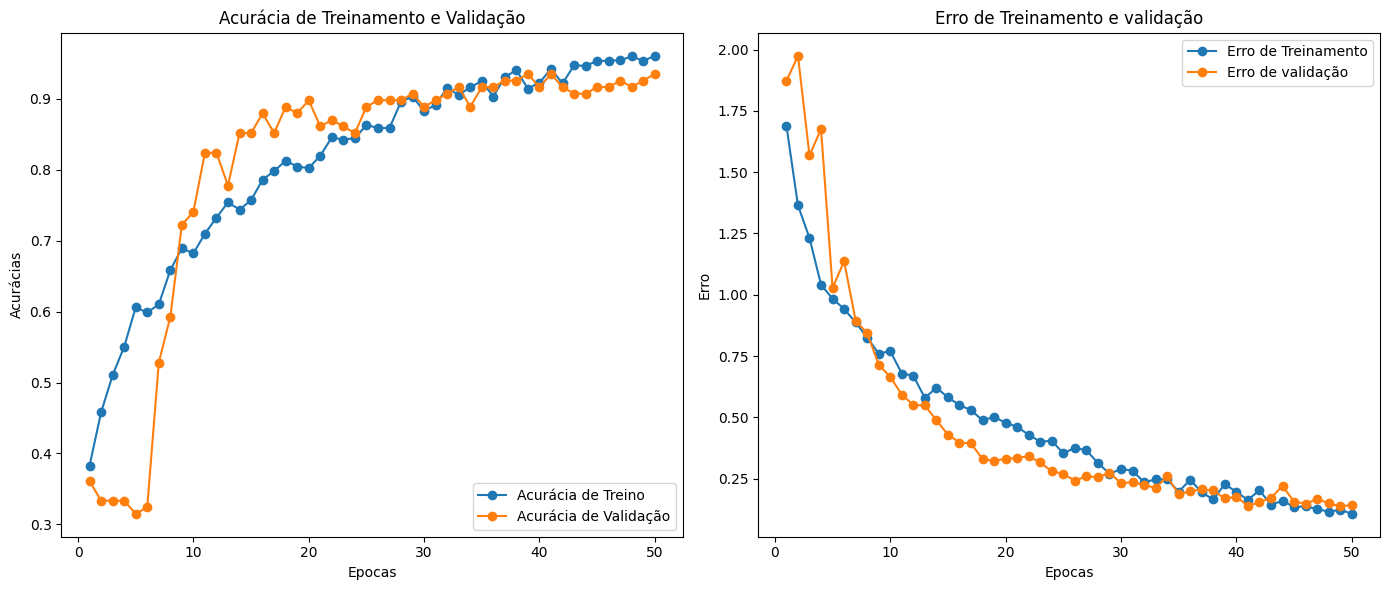

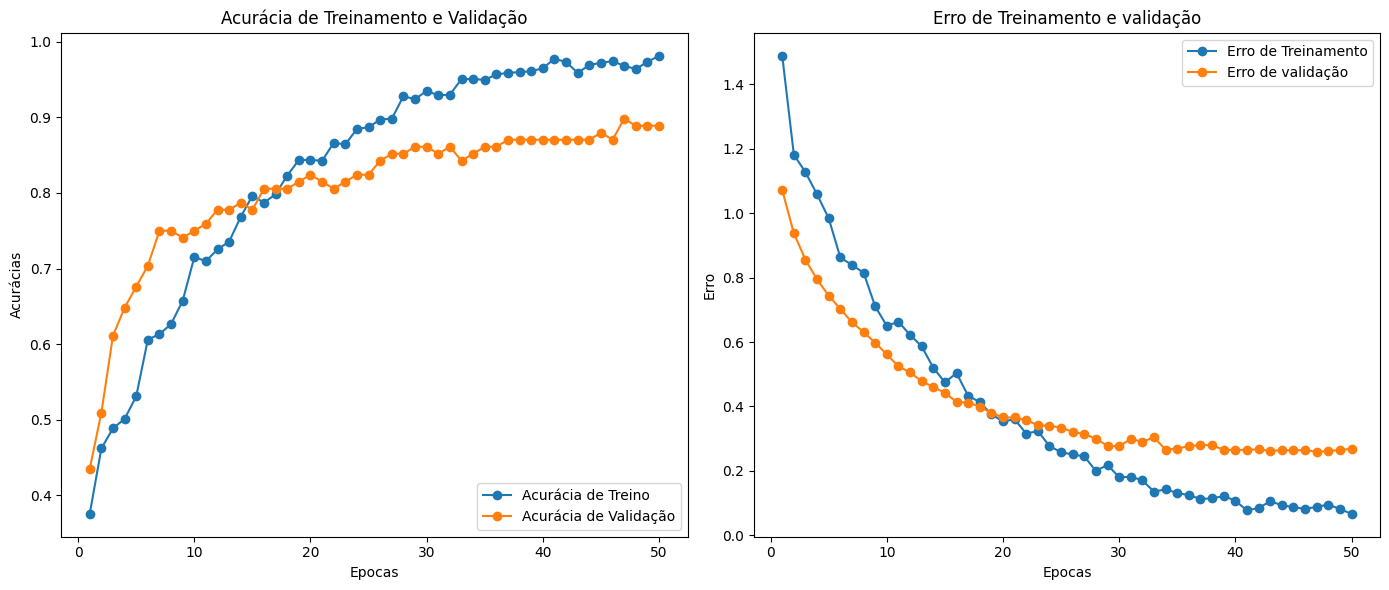

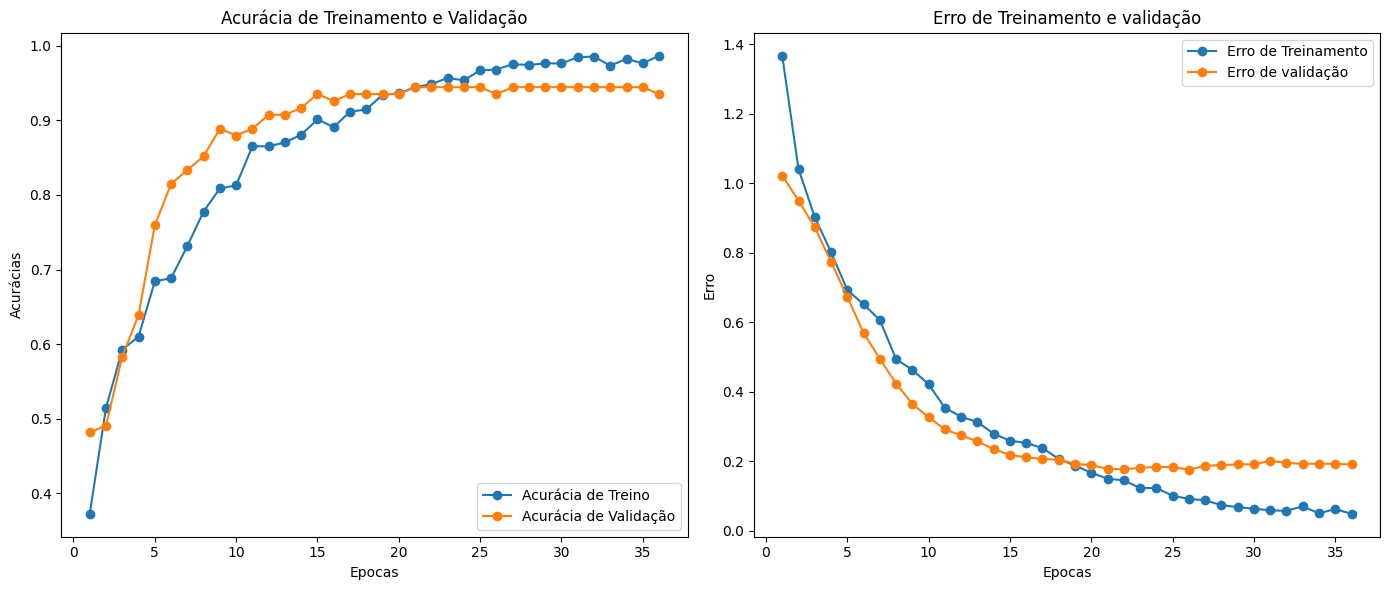

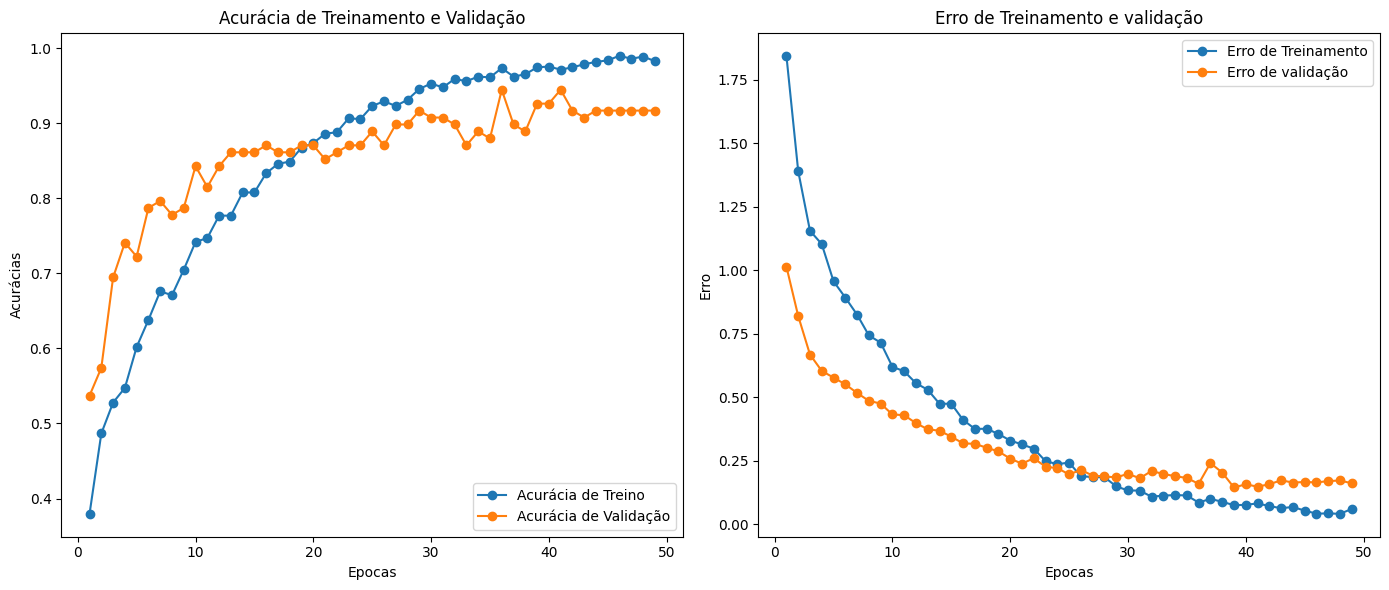

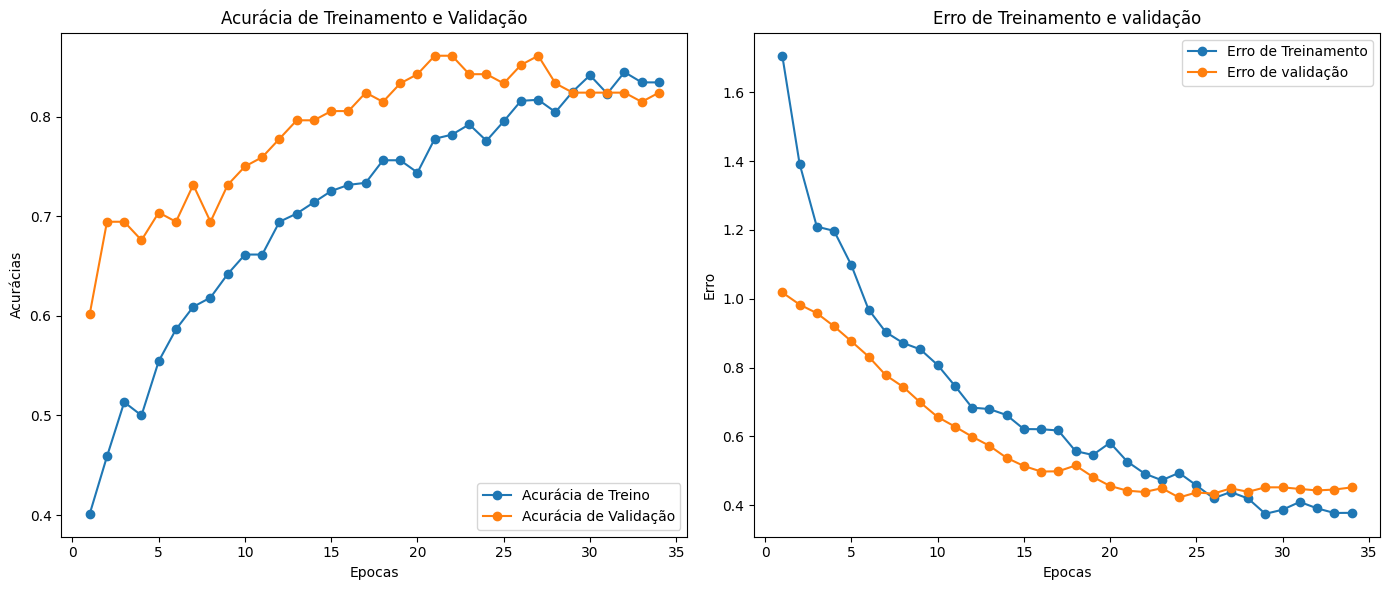

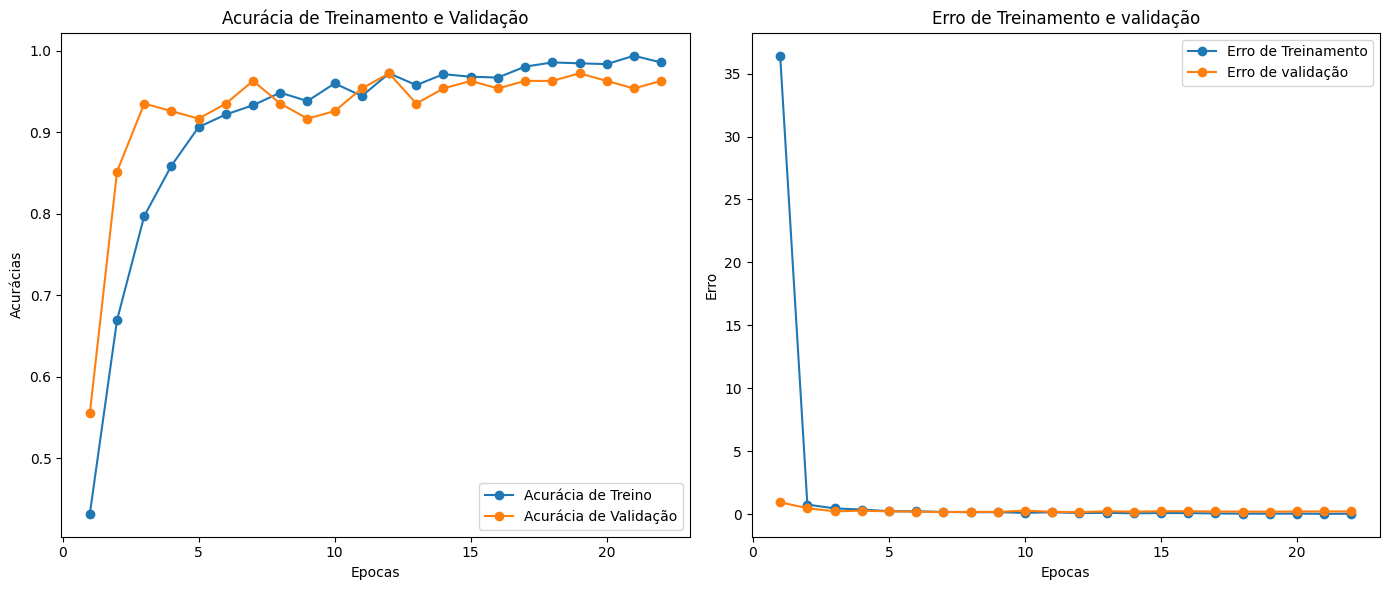

In [ ]:
# Historico dos modelos
#plot_history(history_alexnet)
plot_history(history_resnet)
plot_history(history_vgg)
plot_history(history_dense)
plot_history(history_inception)
plot_history(history_efficient)
plot_history(history_new)

In [ ]:
# Testar
class_names = label_encoder.classes_
#test(model_alexnet, X_additional, y_additional, BATCH_SIZE, 227, class_names)
test(model_resnet, X_additional, y_additional, BATCH_SIZE, 224, class_names)
test(model_vgg, X_additional, y_additional, BATCH_SIZE, 299, class_names)
test(model_densenet, X_additional, y_additional, BATCH_SIZE, 299, class_names)
test(model_inception, X_additional, y_additional, BATCH_SIZE, 299, class_names)
test(model_efficientnet, X_additional, y_additional, BATCH_SIZE, 299, class_names)
test(model_new, X_additional, y_additional, BATCH_SIZE, 227, class_names)

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - accuracy: 0.9448 - loss: 0.1626

Acurácia de Teste: 0.9600
Erro de teste: 0.1318
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step

Relatório de classificação:
                    precision    recall  f1-score   support

Very mild Dementia       0.93      1.00      0.96        25
     Mild Dementia       0.96      1.00      0.98        25
 Moderate Dementia       1.00      0.88      0.94        25

          accuracy                           0.96        75
         macro avg       0.96      0.96      0.96        75
      weighted avg       0.96      0.96      0.96        75

Matriz de Confusão:
[[25  0  0]
 [ 0 25  0]
 [ 2  1 22]]
3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 6s/step - accuracy: 0.8975 - loss: 0.5044

Acurácia de Teste: 0.9200
Erro de teste: 0.3917
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 646ms/step

Relatório de classificação:
                    precision    recall  f1-score   support

Very mild Dementia       0.83      0.96      0.89        25
     Mild Dementia       1.

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 42s 11s/step

Relatório de classificação:
                    precision    recall  f1-score   support

Very mild Dementia       0.86      1.00      0.93        25
     Mild Dementia       0.96      1.00      0.98        25
 Moderate Dementia       1.00      0.80      0.89        25

          accuracy                           0.93        75
         macro avg       0.94      0.93      0.93        75
      weighted avg       0.94      0.93      0.93        75

Matriz de Confusão:
[[25  0  0]
 [ 0 25  0]
 [ 4  1 20]]
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 3s/step - accuracy: 0.8791 - loss: 0.2857

Acurácia de Teste: 0.9067
Erro de teste: 0.2191
3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 3s/step

Relatório de classificação:
                    precision    recall  f1-score   support

Very mild Dementia       0.85      0.92      0.88        25
     Mild Dementia       0.96      1.00      0.98        25
 Moderate Dementia       0.91      0.80      0.85        25

          accuracy        